# Phase 6Q-4 (Qwen3-8B): semi-deep KiL (the policy graph as per-step reasoning)

**Goal:** the second of the three KiL pipelines (RQ1, RQ2, H1). Same agent, model, settings and prose prompt as the baseline (05Q); the only change is that, at every step, the agent plans, retrieves the policy graph's nodes for that plan, cites which hold, and only then acts.

**Result (details in cell 18):** pass^1 0.072 [0.04, 0.11], pass^8 0.000; always / sometimes / never pass 0 / 13 / 37. The lowest of all four arms: below the validator at every k (Δpass^1 −0.333\*), and below the baseline (−0.075\*) and shallow (−0.068\*) at pass^1. The agent's own check is too lenient (65% of verdicts "holds"; it flagged a missing yes before 8 writes, the proxy finds 644) and it sometimes acts against its own check (124 writes). H1 not supported on Qwen3-8B.

**Pipeline (example: "Hi, I want to cancel my flight"):**

```
user input → ① plan: "ACTION: cancel_reservation · PLAN: look up the reservation, then ask for a yes"
           → ② retrieve from airline_policy_graph.json: cancel_reservation's nodes
                (global rules, what to know first, conditions with ANY / ALL groups, required order)
           → ③ check: cite each node: holds / does not hold / unknown + evidence
           → ④ act, conditioned on the check:
                all hold          → list the details, get an explicit yes, then call the tool   ("YES")
                one does not hold → tell the customer it cannot be done and which rule fails      ("NO")
                unknown           → look it up with a tool or ask the customer first
```

①–③ are text-only calls to the same Qwen3-8B (`tool_choice = "none"`), so they never touch the database. Steps ①–④ run at **every** agent step.

**The one difference from the validator (06Q):** the graph shapes the plan **before** the call; nothing checks or blocks the call afterward (no `policy_checker.py`, no veto). Everything else is the same as 06Q: agent, prompt (`wiki.md`), graph, seeds, evaluation. Because the check happens before acting and can read the dialogue, it also covers the graph's dialogue rules (explain the details, get an explicit yes), which a validator on tool calls cannot see.

**Spec check (brief → this notebook):**

| Brief says (quote) | This notebook | Same? |
|---|---|---|
| Semi-deep, "Where knowledge enters": "Planning state" | the plan + check is added as the agent's current planning state before it acts; not a fixed rule list in the system prompt (that is shallow) | yes |
| "Before each tool call" / "reason over the graph at each step" | ①–④ run before **every** agent step: a step can end in a tool call or a reply, so checking every step is the only way to check before each tool call (read and write calls alike). This run: 6,722 steps checked | yes |
| "the agent retrieves the graph nodes relevant to the current dialogue state" | the agent (Qwen) names the graph action(s) the dialogue is about: the customer's request, even when its next step is only a lookup (or "none"); code returns those action nodes' linked nodes from the graph; "none" → the global rules only | yes |
| "must cite which preconditions hold" | one line per node: number, holds / does not hold / unknown, evidence. **Must:** a node left out is asked for once more; still missing → logged as "not cited". This run: 0 nodes left uncited, check lines read 100% | yes |
| Condition examples: "status = pending" or "user confirmed" | the nodes include data conditions and dialogue conditions (G1: details listed and an explicit yes) | yes |
| "generation is conditioned on that check" | the agent's normal call gets the plan and the check in its context; only the latest check is kept there (the current planning state), every check is logged to `plans.jsonl` | yes |
| "it shapes the plan before the call instead of vetoing the call afterward" | no validator, no code that blocks or overrides; the LLM judges each node | yes |
| "That lets it catch dialogue-level violations, such as skipping a required explanation" | G1 is in every check; measured with the same violation cell as 05Q–07Q (skipped confirmation, skipped explanation). Result: the design covers it, but Qwen3-8B's own check rarely flagged it (8 times vs 644 writes without a yes) | yes (design); not achieved in practice |
| "Students with limited compute can stop at shallow and semi-deep, which need only API access" | no training; extra calls to Qwen on vLLM only | yes |
| "pass^k per domain, k = 1 to 8" / curve shape | cell 10, with the validator, shallow and baseline (all seeded) | yes |
| "Policy-violation rate, split into three types" / "by turn position" / "on tasks that still pass" | cell 12 (the same cell as 05Q–07Q; types 2 and 3 are proxies) | yes |
| "Run each task at least 8 times with different simulator seeds" | 50 × 8; trial t gives seed t to every user-simulator call (`qwen_run.py`, the same as 05Q–07Q). Cell 7: Gemini accepts the seed and the same seed repeats a reply | yes, with a caveat: Gemini calls its seed "best effort" |
| "Report means with confidence intervals" | 95% bootstrap CI; paired Δ vs validator, baseline and shallow (cell 11) | yes |
| "hand-check 30 failed trajectories" | 15 failed dialogues here, shown with their planning states (cells 15–17; result 15 agent / 0 simulator); 07Q–09Q add 15 each, 45 in total, pooled in 10Q | yes, more than asked |

**Choices the brief leaves open:** (1) `wiki.md` stays in the prompt, as in the baseline, and the shallow checklist is not added, so semi-deep is not mixed with shallow. (2) "unknown" is allowed: when the data is not looked up yet, the agent says so and looks it up or asks. (3) Only the latest check stays in the context, so dialogues do not grow past the 24k context; all checks are logged.

**Who plays which role:**

| Role | Model | Settings |
|---|---|---|
| Agent (plans, checks and acts) | **Qwen3-8B** on vLLM 0.34.0 | thinking off, temperature 0.0, hermes tool parser; prompt = wiki.md |
| Customer (the user simulator) | **Gemini** `gemini-3.1-flash-lite` | seed = trial number; temperature 1.0 (`deep_run.py`, shown in cell 3) |

**Run first:** 04 (the graph), 06G (`policy_checker.py`, `violations.py`), 07Q cell 4 (`qwen_run.py`), `graph_text.py`, and the seeded 05Q, 06Q, 07Q (comparison lines). This notebook writes `semideep_run.py`. **Runtime:** L4 or larger. **Time (this run, L4):** about 11 h (three model calls per step, about 4× the baseline); run it overnight. If a dialogue hits the 24k limit, cell 8 shows it as "not done": run cell 8 once more; if it fails again, count it as a fail (this run: 1 of 400). Run notes (a lost first run, a Gemini balance top-up mid-run) are in cell 18.

**Order:** 1 → 15 in order (not "Run all"). Then label the 15 dialogues with the buttons in cell 16, run cell 17, and fill cell 18.

**Only re-analysing saved results?** Run cells 1, 2, 3, 4, 9–17. No GPU server needed.

**Output:** `results_qwen_semideep/trial_1..8/` (dialogues, `calls.jsonl`, `seeds.log`, `plans.jsonl`), plus `results_qwen_semideep_config.json`, `_vllm.json`, `_passk.csv`, `_vs_validator.csv`, `_vs_base.csv`, `_vs_shallow.csv`, `_violations.json`, `_plans.json`, `_consistency.json`, `_handcheck.json` and `results_qwen_semideep_handcheck/` (15 dialogues + `labels.xlsx`) for 10Q. Safe to stop: finished tasks are skipped.

In [25]:
# Why: results and code live on Google Drive, so they survive when the Colab runtime resets.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Why: make sure every package the Qwen notebooks need is present, checked one by one. Colab images
# sometimes ship vLLM without litellm, so a single vLLM check lets later cells die on `import litellm`.
# Only missing packages get installed; vLLM takes a few minutes, the rest are quick.
# tau_bench is installed from the project folder with pip. If the normal editable install fails,
# the cell tries the usual fixes one by one and stops at the first that works:
#   1. --no-build-isolation (uses Colab's own setuptools instead of a fresh, newer one)
#   2. a stale tau_bench.egg-info on Drive: renamed (never deleted), pip writes a new one
#   3. a normal (non-editable) install; runs start in ROOT, so they still use the folder's code
# If all fail, the real error lines are shown (not only pip's "subprocess-exited-with-error").
import importlib, importlib.util, os, site, subprocess, time
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
PKGS = [("litellm", "litellm"), ("vllm", "vllm"), ("peft", "peft"), ("mcp", "mcp")]

def have(mod):
    importlib.invalidate_caches()
    try:
        site.main()            # pick up what pip just added to this running kernel
    except Exception:
        pass
    try:
        return importlib.util.find_spec(mod) is not None
    except Exception:
        return False

def pip(args):
    r = subprocess.run(f"pip install -q {args}", shell=True, capture_output=True, text=True, cwd="/content")
    return r.returncode == 0, (r.stdout + r.stderr).splitlines()

def real_error(lines):
    # the useful lines sit between pip's own notes: tracebacks, "error:" lines, missing files
    skip = ("subprocess-exited-with-error", "This error originates", "note:", "╰─>", "[end of output]")
    keep = [l for l in lines if l.strip() and not any(s in l for s in skip)
            and any(w in l for w in ("Error", "error", "No such file", "Traceback", 'File "'))]
    return keep[-8:] or lines[-8:]

def install_tau_bench():
    ok, out = pip(f"-e {ROOT}")
    if ok: return "installed (editable)", []
    pip("setuptools wheel")
    ok, out = pip(f"--no-build-isolation -e {ROOT}")
    if ok: return "installed (editable, no build isolation)", []
    egg = f"{ROOT}/tau_bench.egg-info"
    if os.path.isdir(egg):
        os.rename(egg, f"{egg}_old_{time.strftime('%m%d_%H%M')}")
        ok, out = pip(f"--no-build-isolation -e {ROOT}")
        if ok: return "installed (editable, old egg-info renamed)", []
    ok, out = pip(f"--no-build-isolation {ROOT}")
    if ok: return "installed (normal, not editable)", []
    return "❌ still missing", real_error(out)

rows, errors = [], []
for mod, spec in PKGS:                       # litellm first: tau_bench needs it
    if have(mod):
        rows.append({"package": mod, "action": "already there"}); continue
    ok, out = pip(spec)
    if not ok: errors += real_error(out)
    if mod == "vllm":
        subprocess.run("pip uninstall -y -q torchao", shell=True, capture_output=True)  # clashes with vLLM
    rows.append({"package": mod, "action": "installed" if have(mod) else "❌ still missing"})

if have("tau_bench"):
    rows.insert(0, {"package": "tau_bench", "action": "already there"})
else:
    action, err = install_tau_bench()
    rows.insert(0, {"package": "tau_bench", "action": action if have("tau_bench") else "❌ still missing"})
    errors = err + errors

display(pd.DataFrame(rows).style.set_properties(**{"text-align": "left"}).hide(axis="index"))
if errors:
    print("Real error lines:\n" + "\n".join(errors[-10:]))

package,action
tau_bench,already there
litellm,already there
vllm,already there
peft,already there
mcp,already there


In [26]:
# Why: every arm must use the same frozen settings, or the comparison is not fair. The agent
# settings come from settings_deep.py and settings_gemini.py. The agent temperature is set here
# once and used by cells 5 and 6; an assert stops the run if it ever drifts from settings_gemini.
# Semi-deep KiL: trial t gives seed t to every user-simulator call, the same 8 seeds as 05Q-07Q.
# The comparison lines (05Q, 06Q, 07Q, all seeded) are read, never written to.
# The Gemini key comes from Colab Secrets and is never printed.
import os, sys, json, time, glob, importlib, logging, warnings
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, ROOT)
os.chdir(ROOT)
NEED = ["settings_gemini.py", "settings_deep.py", "deep_run.py", "qwen_run.py", "policy_checker.py",
        "violations.py", "airline_policy_graph.json", "passk.py", "graph_text.py"]
missing = [f for f in NEED if not os.path.exists(f)]
assert not missing, f"missing {missing}: run 04 and 06G first; qwen_run.py is written by 07Q cell 4"

importlib.invalidate_caches()
import settings_gemini, settings_deep, passk
importlib.reload(settings_gemini); importlib.reload(settings_deep)
from settings_gemini import (MODEL as USER_MODEL, ENV, N_TASKS, N_TRIALS,
                             TEMPERATURE, CONCURRENCY, PRICE_IN, PRICE_OUT)
from settings_deep import BASE_MODEL, SERVED_BASE, MAX_MODEL_LEN, GPU_MEM, AGENT_THINKING

AGENT_TEMP = 0.0                                    # one source of truth for cells 6 and 7
SEEDS = True        # simulator seed = trial number (the same as 07Q)
VALIDATOR = False                               # no validator: nothing checks or blocks a call afterward
assert TEMPERATURE == AGENT_TEMP, f"settings_gemini.TEMPERATURE is {TEMPERATURE}, expected {AGENT_TEMP}"
TEMP_LINES = [f"line {i}: {l.strip()[:90]}" for i, l in enumerate(open("deep_run.py"), 1) if "temperature" in l.lower()]
USER_TEMP = "see deep_run.py lines below"
ARM, OUT = "semideep", "results_qwen_semideep"
BASE_OUT, VAL_OUT, SHAL_OUT = "results_qwen_base", "results_qwen_validator", "results_qwen_shallow"
ARMS = [(f"qwen {ARM} (08Q)", OUT, "#f2a600"),         # name, folder, color (H7); this arm first
        ("qwen validator (06Q)", VAL_OUT, "#f47230"),     # comparison only, never written to
        ("qwen shallow (07Q)", SHAL_OUT, "#00b894"),
        ("qwen base (05Q)", BASE_OUT, "#257de0")]
COMPARE = [("validator", VAL_OUT, "vs_validator"),   # H1: a KiL pipeline must beat the validator
           ("baseline", BASE_OUT, "vs_base"),
           ("shallow", SHAL_OUT, "vs_shallow")]      # professor: compare the three pipelines

warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)
from google.colab import userdata
os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
os.environ["VLLM_BASE"] = "http://localhost:8000/v1"

def show(df):
    # headers and cells both left-aligned, so long wrapped headers sit over their own column
    display(df.style.set_properties(**{"text-align": "left"})
              .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
              .hide(axis="index"))

_TAB = {}
def tab_of(folder, reload=False):
    # read the saved dialogues off Drive once; cells 9-17 share the copy
    import passk
    if reload or folder not in _TAB:
        importlib.reload(passk)
        _TAB[folder] = passk.table(f"{ROOT}/{folder}")
    return _TAB[folder]

def has_checklist(r):
    # the shallow checklist must NOT be in this arm's prompt (semi-deep retrieves per step instead)
    return any("Policy checklist" in str(m.get("content", "")) for m in (r.get("traj") or [])[:3] if isinstance(m, dict))

def n_lines(path):
    return sum(1 for l in open(path) if l.strip()) if os.path.exists(path) else 0
n_seeded = lambda folder: n_lines(f"{folder}/seeds.log")
n_blocks = lambda folder: n_lines(f"{folder}/blocks.jsonl")
n_plans = lambda folder: n_lines(f"{folder}/plans.jsonl")    # one row per agent step (plan + check)

def seeded_run(out):
    cfg = f"{ROOT}/{out}_config.json"
    return os.path.exists(cfg) and "simulator_seed" in json.load(open(cfg))

found = lambda d: "(found)" if os.path.isdir(f"{ROOT}/{d}") else "⚠️ not found"
show(pd.DataFrame([
    {"setting": "agent model", "value": f"{BASE_MODEL} (served as {SERVED_BASE}), thinking {AGENT_THINKING}"},
    {"setting": "agent temperature", "value": str(AGENT_TEMP)},
    {"setting": "policy in prompt", "value": "wiki.md only (as τ-bench ships it), the same as the baseline"},
    {"setting": "semi-deep", "value": "every agent step: plan -> graph nodes for that action -> cite holds / does not hold / unknown -> act (semideep_run.py)"},
    {"setting": "validator", "value": "off: nothing checks or blocks a call afterward"},
    {"setting": "user simulator", "value": f"{USER_MODEL} (Gemini, same as every arm)"},
    {"setting": "user temperature", "value": USER_TEMP},
    {"setting": "simulator seed", "value": "trial number 1..8, passed to every user-simulator call (qwen_run.py)"},
    {"setting": "env / tasks / trials", "value": f"{ENV} / {N_TASKS} / {N_TRIALS}"},
    {"setting": "concurrency", "value": str(CONCURRENCY)},
    {"setting": "output folder", "value": f"{OUT} " + ("(run found)" if seeded_run(OUT) else "(no run yet)")},
    {"setting": "compared with", "value": "; ".join(f"{d} {found(d)}" for _, d, _ in ARMS[1:])},
] + [{"setting": "deep_run.py", "value": l} for l in TEMP_LINES or ["no line mentions temperature: provider default"]]))

setting,value
agent model,"Qwen/Qwen3-8B (served as qwen3-8b), thinking False"
agent temperature,0.0
policy in prompt,"wiki.md only (as τ-bench ships it), the same as the baseline"
semi-deep,every agent step: plan -> graph nodes for that action -> cite holds / does not hold / unknown -> act (semideep_run.py)
validator,off: nothing checks or blocks a call afterward
user simulator,"gemini-3.1-flash-lite (Gemini, same as every arm)"
user temperature,see deep_run.py lines below
simulator seed,"trial number 1..8, passed to every user-simulator call (qwen_run.py)"
env / tasks / trials,airline / 50 / 8
concurrency,4


In [8]:
# Why: write the semi-deep runner and show what the agent will be asked at each step. semideep_run.py
# hooks the agent's model call; at every step it runs plan -> retrieve graph nodes -> cite each one ->
# act, then runs qwen_run.py exactly as 05Q-07Q (simulator seed per trial, deep_run.py unchanged).
# Saved from a string, so there is no "Overwriting" noise; rewritten only if the text changed.
import hashlib, importlib, graph_text as gt
CODE = r'''# Semi-deep KiL (08Q): "Before each tool call, the agent retrieves the graph nodes relevant to the
# current dialogue state and must cite which preconditions hold; generation is conditioned on that
# check." The one difference from the validator (06Q): the graph shapes the plan BEFORE the call;
# nothing checks or blocks the call afterward (no policy_checker, no veto).
#
# At EVERY agent step (a step may end in a tool call or a reply, so checking every step is the only
# way to check before each tool call), three calls to the same agent model (Qwen3-8B):
#   1. plan      the agent says what it will do next and which graph action(s) the current dialogue
#                state is about: the customer's request, even when the next step is only a lookup
#                (or "none" when no action is in play yet)
#   2. check     code retrieves those actions' nodes from airline_policy_graph.json (conditions with
#                their OR / AND groups, ask-first items, global rules, required order); the agent
#                must cite each one: holds / does not hold / unknown, with its evidence. A missing
#                item is asked for once more ("must cite").
#   3. act       the normal agent call, with the plan and the check added as the agent's current
#                planning state. Only the latest check is in the context; every check is logged.
# Steps 1-2 are text-only calls (tool_choice "none"), so they never reach the database.
# Prompt = wiki.md as in the baseline; the shallow checklist is NOT added.
# Then qwen_run.py runs as for every Qwen arm (simulator seed per trial, deep_run.py unchanged).
import json
import os
import re
import runpy
import sys
import threading

import litellm
import graph_text as gt

G = gt.load()
ACTIONS = {a["action"]: a for a in G["actions"]}
PLAN_LOG = os.environ.get("PLAN_LOG", "plans.jsonl")
VERDICTS = ("holds", "does not hold", "unknown")
_lock = threading.Lock()
_local = threading.local()                       # one task per worker thread (tau-bench ThreadPool)


# ---------------------------------------------------------------- graph retrieval
def _alt(c):
    """One line for a condition; OR / AND groups list their alternatives inline."""
    if "any_of" in c or "all_of" in c:
        kind, subs = ("ANY ONE of", c["any_of"]) if "any_of" in c else ("ALL of", c["all_of"])
        return f"{kind}: " + "; ".join(f"({chr(97 + j)}) {_alt(s)}" for j, s in enumerate(subs))
    txt = f"{c['condition']} [{c['source']}]"
    if "must_happen_before" in c:
        txt += f" (must be done before {c['must_happen_before']})"
    return txt


def nodes_for(actions):
    """The graph nodes the check must cite, as (id, text), for a list of graph actions (empty =
    no action in play): global rules that apply everywhere or to one of the actions, then per
    action what to know first and its conditions. Condition ids follow policy_checker's rule ids
    ("<action>/c<k>"), so every verdict can later be compared with the code checker."""
    if isinstance(actions, str):
        actions = [] if actions == "none" else [actions]
    items = [(f"G/{r['source']}", f"{r['condition']} [{r['source']}]") for r in G["global_rules"]
             if "applies_to" not in r or set(actions) & set(r["applies_to"])]
    for action in actions:
        a = ACTIONS[action]
        items += [(f"{action}/info{k}", f"{action}: known from the user or the tools: {i['info']} [{i['source']}]")
                  for k, i in enumerate(a.get("needs_info", []))]
        items += [(f"{action}/c{k}", f"{action}: {_alt(c)}") for k, c in enumerate(a["conditions"])]
    return items


# ---------------------------------------------------------------- prompts
def plan_prompt():
    names = ", ".join(ACTIONS)
    return ("[Planning step: write for yourself, the customer does not see this.] "
            "Before you act, state your plan. Answer in exactly two lines:\n"
            f"ACTION: the action(s) from this list that the customer's current request is about, even if "
            f"your next step is only a lookup: {names}. Use commas for more than one; write none if no "
            "action is in play yet\n"
            "PLAN: one sentence: what you will do next and why")


def check_prompt(plan, action, items):
    rules = "\n".join(f"{n}. {t}" for n, (_, t) in enumerate(items, 1))
    where = f"for {action}" if action != "none" else "that apply to every conversation"
    return ("[Policy check: write for yourself, the customer does not see this.] "
            f"Your plan: {plan}\nThese are the policy graph's rules {where}:\n{rules}\n\n"
            "Check every rule against this conversation and the tool results so far. For EACH rule, "
            "write one short line exactly as: <number> | holds / does not hold / unknown | <evidence in "
            "at most 12 words: the tool value or what the customer said; for unknown, what is missing>. "
            "For an ANY ONE group, say which option holds. No table, no heading, nothing else.\n"
            "Example:\n1 | holds | user id mia_li_3668 found by get_user_details\n"
            "2 | unknown | customer has not said yes yet")


def act_note(plan, action, items, verdicts):
    lines = "\n".join(f"{n}. {t} -> {verdicts[i][0]} ({verdicts[i][1]})"
                      for n, (i, t) in enumerate(items, 1))
    return ("[Your planning state for this step: your own plan and policy check, not from the "
            f"customer.]\nPlan: {plan}\nAction in the policy graph: {action}\n"
            + (f"Check:\n{lines}\n" if items else "")
            + "Now make your next step follow this check. If a rule does not hold, do not do the "
              "action: tell the customer it cannot be done and which rule fails. If a rule is "
              "unknown, look it up with a tool or ask the customer first. Write your next message "
              "to the customer or make your next tool call.")


# ---------------------------------------------------------------- parsing
def parse_plan(text):
    """-> (comma-joined graph actions, or "none"; None if a name is not a graph action), plan"""
    text = text or ""
    m = re.search(r"ACTION:\s*([^\n]+)", text)
    names = [x.strip(" .`*'\"") for x in (m.group(1).split(",") if m else [])]
    names = [x for x in names if x]
    p = re.search(r"PLAN:\s*(.+)", text)
    plan = p.group(1).strip() if p else text.strip()[:300]
    if names == ["none"]:
        return "none", plan
    ok = names and all(x in ACTIONS for x in names)
    return (",".join(dict.fromkeys(names)) if ok else None), plan


_VERDICT = re.compile(r"does\s*n[o']?t\s+hold|not\s+hold|not\s+met|unmet|unknown|unclear|holds?|met|"
                      r"\btrue\b|\bfalse\b|\byes\b|\bno\b", re.I)


def _verdict(word):
    w = word.lower()
    if w in ("unknown", "unclear"):
        return "unknown"
    if any(x in w for x in ("not", "n't", "unmet")) or w in ("false", "no"):
        return "does not hold"
    return "holds"


def parse_check(text, n_items):
    """Lenient: '3 | holds | ...', '| 3 | Holds | ... |' (a table), '3. Holds - ...', 'Rule 3: does not
    hold (...)', '**3** | unknown | ...'. The first number on the line is the rule; the first verdict
    word after it is the verdict; the rest is the evidence."""
    out = {}
    for line in (text or "").splitlines():
        m = re.match(r"[\s|*#>\-]*(?:rule\s*)?(\d+)\b[\s.):*|\-]*(.*)", line, re.I)
        if not m or not (1 <= int(m.group(1)) <= n_items) or int(m.group(1)) in out:
            continue
        v = _VERDICT.search(m.group(2))
        if not v:
            continue
        ev = m.group(2)[v.end():].strip(" |:-–—*()").strip()
        out[int(m.group(1))] = (_verdict(v.group(0)), ev[:200])
    return out


# ---------------------------------------------------------------- the per-step hook
def _side(kwargs, note, max_tokens):
    """Text-only call to the same agent model; never a tool call, never reaches the database."""
    kw = dict(kwargs)
    kw["messages"] = list(kwargs["messages"]) + [{"role": "user", "content": note}]
    kw["tool_choice"] = "none"
    kw["max_tokens"] = max_tokens
    return (litellm.completion(**kw).choices[0].message.content or "").strip()


def semideep(*args, **kwargs):
    # litellm.completion is looked up at call time, so deep_run.py's routing (agent -> vLLM)
    # and call log are used for all three calls
    step = getattr(_local, "step", 0) + 1
    _local.step = step
    row = {"task_id": getattr(_local, "task", None), "step": step}

    text = _side(kwargs, plan_prompt(), 120)
    action, plan = parse_plan(text)
    if action is None:                           # must name a graph action: ask once more
        text = _side(kwargs, plan_prompt() + "\nThe ACTION line must be one of the names above.", 120)
        action, plan = parse_plan(text)
        row["plan_retry"] = True
    action = action or "none"

    items = nodes_for([] if action == "none" else action.split(","))
    verdicts = {}
    if items:
        raw = _side(kwargs, check_prompt(plan, action, items), 600)
        got = parse_check(raw, len(items))
        row["check_raw"] = raw[:1200]                # Qwen's own words, to audit the parser
        miss = [n for n in range(1, len(items) + 1) if n not in got]
        if miss:                                 # "must cite": ask once for the missing ones
            more = _side(kwargs, check_prompt(plan, action, items)
                         + f"\nYou did not answer rules {', '.join(map(str, miss))}. Answer every rule.", 600)
            got.update({k: v for k, v in parse_check(more, len(items)).items() if k not in got})
            row["check_retry"] = miss
        verdicts = {i: got.get(n, ("unknown", "not cited")) for n, (i, _) in enumerate(items, 1)}

    kw = dict(kwargs)
    kw["messages"] = list(kwargs["messages"]) + [{"role": "user", "content": act_note(plan, action, items, verdicts)}]
    res = litellm.completion(*args, **kw)
    m = res.choices[0].message
    calls = m.tool_calls or []
    row.update(action=action, plan=plan, check={i: v for i, v in verdicts.items()},
               next="tool:" + calls[0].function.name if calls else "reply")
    with _lock, open(PLAN_LOG, "a") as f:
        f.write(json.dumps(row) + "\n")
    return res


# ---------------------------------------------------------------- install, then run as every Qwen arm
def install():
    import tau_bench.agents.tool_calling_agent as agent_mod
    from tau_bench.envs.base import Env
    real_reset = Env.reset

    def reset(self, task_index=None):
        _local.task, _local.step = task_index, 0            # plans.jsonl rows know their task
        return real_reset(self, task_index)

    Env.reset = reset
    agent_mod.completion = semideep


if __name__ == "__main__":
    install()
    here = os.path.dirname(os.path.abspath(__file__))
    sys.argv[0] = os.path.join(here, "qwen_run.py")
    runpy.run_path(os.path.join(here, "qwen_run.py"), run_name="__main__")
'''
old = open(f"{ROOT}/semideep_run.py").read() if os.path.exists(f"{ROOT}/semideep_run.py") else None
if old != CODE:
    open(f"{ROOT}/semideep_run.py", "w").write(CODE)
qr = open(f"{ROOT}/qwen_run.py").read()
import semideep_run as sdr; importlib.reload(sdr)      # only reads its functions; install() is not called
show(pd.DataFrame([{"item": "semideep_run.py", "value": ("unchanged" if old == CODE else "updated" if old else "written")
                                                      + " · id " + hashlib.md5(CODE.encode()).hexdigest()[:8]},
                   {"item": "qwen_run.py id (same as 05Q-07Q)", "value": hashlib.md5(qr.encode()).hexdigest()[:8]},
                   {"item": "graph actions the agent can name", "value": ", ".join(sdr.ACTIONS) + ", none"}]))
show(pd.DataFrame([{"action": a, "nodes the check must cite": len(sdr.nodes_for([] if a == "none" else [a]))}
                   for a in list(sdr.ACTIONS) + ["none"]]))
print("Example: the check the agent gets for cancel_reservation\n")
print(sdr.check_prompt("<the agent's plan>", "cancel_reservation", sdr.nodes_for(["cancel_reservation"])))

item,value
semideep_run.py,unchanged · id 7dd0a89f
qwen_run.py id (same as 05Q-07Q),7c5c44b9
graph actions the agent can name,"book_reservation, update_reservation_flights, upgrade_cabin, update_reservation_baggages, update_reservation_passengers, cancel_reservation, send_certificate, none"


action,nodes the check must cite
book_reservation,18
update_reservation_flights,11
upgrade_cabin,9
update_reservation_baggages,9
update_reservation_passengers,8
cancel_reservation,9
send_certificate,7
none,4


Example: the check the agent gets for cancel_reservation

[Policy check: write for yourself, the customer does not see this.] Your plan: <the agent's plan>
These are the policy graph's rules for cancel_reservation:
1. give no information, knowledge or procedures not given by the user or the tools; no subjective recommendations or comments [G2]
2. make one tool call at a time; never call a tool and reply to the user in the same turn [G3]
3. deny user requests that are against this policy [G4]
4. transfer to a human agent if and only if the request cannot be handled by any of the agent's actions [G5]
5. cancel_reservation: known from the user or the tools: user_id [C1]
6. cancel_reservation: known from the user or the tools: reservation_id [C1]
7. cancel_reservation: known from the user or the tools: cancel_reason: change of plan, airline cancelled flight, or other reasons [C1]
8. cancel_reservation: no segment of the trip is flown yet (only the whole unflown trip can be cancelled) [C3]


In [10]:
# Why: start Qwen3-8B on vLLM and test it. The GPU decides the settings: >= 40 GB (A100, G4, H100)
# uses the full 32k context; a 24 GB L4 only fits 24k (recorded in the config).
# max-num-seqs is capped at 2 x concurrency: the default (256) reserves warmup memory we never use,
# and on an L4 that leaves too little KV cache for 24k. The vLLM version is saved, since a newer
# vLLM can behave differently from the one an earlier arm used.
# Not needed to re-analyse saved results: for that, run cells 1, 2, 3, 4, 9-17 only.
import subprocess, time, json, urllib.request, importlib.metadata, litellm
os.makedirs(f"{ROOT}/logs_qwen", exist_ok=True)
smi = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout.strip()
assert ", " in smi, "no GPU found: Runtime > Change runtime type > pick a GPU"
GPU_NAME, gb = smi.splitlines()[0].split(", ")
GPU_GB = int(gb) / 1024
RUN_LEN, RUN_MEM = (MAX_MODEL_LEN, GPU_MEM) if GPU_GB >= 39 else (24576, "0.93")
MAX_SEQS = 2 * CONCURRENCY
VLLM_VER = importlib.metadata.version("vllm")
VLLM_LOG = f"{ROOT}/logs_qwen/vllm.log"
json.dump({"vllm": VLLM_VER, "max_num_seqs": MAX_SEQS, "gpu": GPU_NAME, "max_model_len": RUN_LEN},
          open(f"{ROOT}/{OUT}_vllm.json", "w"), indent=2)

def server_up():
    try:
        urllib.request.urlopen("http://localhost:8000/v1/models", timeout=5); return True
    except Exception:
        return False

t0 = time.time()
reused = server_up()
if not reused:
    cmd = (f"vllm serve {BASE_MODEL} --served-model-name {SERVED_BASE} --max-model-len {RUN_LEN} "
           f"--gpu-memory-utilization {RUN_MEM} --max-num-seqs {MAX_SEQS} "
           f"--enable-auto-tool-choice --tool-call-parser hermes --port 8000")
    with open(VLLM_LOG, "w") as lf:               # the server keeps its own handle; ours is closed
        server = subprocess.Popen(cmd, shell=True, stdout=lf, stderr=subprocess.STDOUT)
    while not server_up():
        if server.poll() is not None or time.time() - t0 > 1200:
            err = [l for l in open(VLLM_LOG).read().splitlines() if "error" in l.lower()][-3:]
            raise RuntimeError("vLLM did not start. Last errors in logs_qwen/vllm.log:\n" + "\n".join(err))
        time.sleep(10)

kw = dict(model=SERVED_BASE, custom_llm_provider="hosted_vllm", api_base=os.environ["VLLM_BASE"], api_key="none",
          temperature=AGENT_TEMP, extra_body={"chat_template_kwargs": {"enable_thinking": AGENT_THINKING}})
tools = [{"type": "function", "function": {"name": "get_reservation_details", "description": "Look up a reservation",
          "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}}, "required": ["reservation_id"]}}}]
msg = [{"role": "user", "content": "Look up reservation ABC123."}]
r1 = litellm.completion(**kw, tools=tools, messages=msg)
try:
    r2 = litellm.completion(**kw, tools=tools, tool_choice="none", messages=msg)
    none_ok = "✅" if not r2.choices[0].message.tool_calls else "⚠️ returned a call (ignored by kil_qwen.py)"
except Exception as e:
    none_ok = f"⚠️ not supported ({type(e).__name__}); kil_qwen.py falls back"
show(pd.DataFrame([
    {"check": "GPU", "result": f"{GPU_NAME}, {GPU_GB:.0f} GB"},
    {"check": "vLLM version", "result": VLLM_VER},
    {"check": "max length", "result": f"{RUN_LEN}" + ("" if RUN_LEN == MAX_MODEL_LEN else "  ⚠️ full setting is 32768: note in the report")},
    {"check": "max num seqs", "result": str(MAX_SEQS)},
    {"check": "vLLM", "result": "reused (already running)" if reused else f"started in {(time.time() - t0) / 60:.1f} min"},
    {"check": "tool call", "result": "✅" if r1.choices[0].message.tool_calls else "❌"},
    {"check": "text-only call (semi-deep needs it)", "result": none_ok}]))

check,result
GPU,"NVIDIA L4, 22 GB"
vLLM version,0.34.0
max length,24576 ⚠️ full setting is 32768: note in the report
max num seqs,8
vLLM,reused (already running)
tool call,✅
text-only call (semi-deep needs it),✅


In [11]:
# Why: one function runs this arm for 8 trials x 50 tasks, one folder per trial, with semideep_run.py
# (plan + check at every agent step, then qwen_run.py: seed, then deep_run.py: agent -> Qwen on vLLM,
# user -> Gemini). Trial t uses simulator seed t, the same seeds as 05Q-07Q. Every step's plan and
# check go to plans.jsonl. No validator: nothing checks or blocks a call afterward.
# Finished tasks are skipped, so a stopped run can simply be started again. The config is written
# only when a task really runs, so a rerun of a finished arm never overwrites its config.
import time, json, importlib, passk; importlib.reload(passk)

def keep_old_run(out):
    # a run made with another semideep_run.py must not be mixed with this one (finished tasks would
    # be skipped): its folder and files are renamed to <out>_old_<runner id>, never deleted
    cfg = f"{ROOT}/{out}_config.json"
    if not os.path.exists(cfg):
        return None
    was = json.load(open(cfg)).get("semideep_run")
    now = hashlib.md5(CODE.encode()).hexdigest()[:8]
    if was == now:
        return None
    tag = f"{out}_old_{was or 'unknown'}"
    for a in [out] + [f"{out}_{x}" for x in ("config.json", "vllm.json")] + glob.glob(f"{ROOT}/logs_qwen/{out}_trial_*.log"):
        a = os.path.relpath(a, ROOT) if a.startswith(ROOT) else a
        if os.path.exists(f"{ROOT}/{a}"):
            os.rename(f"{ROOT}/{a}", f"{ROOT}/{a.replace(out, tag, 1)}")
    return tag

def run_arm(out, tasks=None, trials=None, arm=ARM):
    moved = keep_old_run(out)
    if moved:
        print(f"an earlier run used another semideep_run.py: kept as {moved} (not deleted)")
    os.environ["DEEP_VALIDATOR"] = "1" if VALIDATOR else "0"
    os.environ["QWEN_SHALLOW"] = "0"
    config = {"agent": BASE_MODEL, "user": USER_MODEL, "arm": arm, "validator": VALIDATOR,
              "policy": "wiki.md only; semi-deep: plan -> graph nodes -> cite each -> act, every step",
              "semideep_run": hashlib.md5(CODE.encode()).hexdigest()[:8],
              "simulator_seed": "trial number (trial_1 -> 1 ... trial_8 -> 8)",
              "agent_temperature": AGENT_TEMP, "user_temperature": TEMP_LINES,
              "gpu": GPU_NAME, "max_model_len": RUN_LEN, "max_num_seqs": MAX_SEQS, "vllm": VLLM_VER}
    rows, wrote = [], False
    for trial in (trials or range(1, N_TRIALS + 1)):
        folder = f"{ROOT}/{out}/trial_{trial}"
        os.makedirs(folder, exist_ok=True)
        want = set(tasks if tasks is not None else range(N_TASKS))
        todo = sorted(want - passk.done_tasks(folder))
        if not todo:
            rows.append({"trial": trial, "ran": 0, "min": "-", "not done": 0, "note": "already done"})
            continue
        if not wrote:
            json.dump(config, open(f"{ROOT}/{out}_config.json", "w"), indent=2); wrote = True
        print(f"trial {trial}: running {len(todo)} tasks (simulator seed {trial}) ...", flush=True)
        t0 = time.time()
        os.environ["SIM_SEED"] = str(trial)
        os.environ["SEED_LOG"] = f"{folder}/seeds.log"
        os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
        os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
        os.environ["PLAN_LOG"] = f"{folder}/plans.jsonl"
        ids = " ".join(map(str, todo))
        log = f"{ROOT}/logs_qwen/{out}_trial_{trial}.log"
        !cd {ROOT} && python semideep_run.py --env {ENV} --agent-strategy tool-calling \
          --model {SERVED_BASE} --model-provider hosted_vllm \
          --user-model {USER_MODEL} --user-model-provider gemini \
          --user-strategy llm --num-trials 1 --temperature {AGENT_TEMP} \
          --task-ids {ids} --max-concurrency {CONCURRENCY} \
          --log-dir {folder} >> {log} 2>&1
        left = len(want - passk.done_tasks(folder))
        note = ""
        if left:
            bad = [l for l in open(log).read().splitlines() if "Error" in l or "Traceback" in l][-1:]
            note = bad[0][:80] if bad else f"see logs_qwen/{out}_trial_{trial}.log"
        rows.append({"trial": trial, "ran": len(todo), "min": f"{(time.time() - t0) / 60:.1f}",
                     "not done": left, "note": note})
    _TAB.pop(out, None)                           # results changed: drop the cached dialogues
    show(pd.DataFrame(rows))

In [8]:
# Why: before the full run, check the three things this arm depends on:
#  1. the Gemini API accepts a seed, and the same seed gives the same reply (Gemini calls this
#     "best effort"), while another seed may differ: 3 direct calls at the simulator's default settings
#  2. a 2-task run finishes with no API errors, every user-simulator call was seeded, the shallow
#     checklist is NOT in the prompt, the validator is off, and every agent step has a plan + check
#     (plans.jsonl); one dialogue's planning states are printed to read before the full run
#  3. how long and how much the full run will take (the formula matched the real 05Q and 07Q runs)
import shutil, litellm
probe = [{"role": "system", "content": "You are a customer of an airline. Write one short, natural sentence "
                                      "asking to change your flight. Vary the wording."},
         {"role": "user", "content": "Hi! How can I help you today?"}]
def ask(seed):
    r = litellm.completion(model=USER_MODEL, custom_llm_provider="gemini", messages=probe, seed=seed)
    return r.choices[0].message.content.strip()
try:
    a1, a2, b1 = ask(1), ask(1), ask(2)
    seed_ok, same, diff = True, a1 == a2, a1 != b1
except Exception as e:
    seed_ok, same, diff, a1 = False, False, False, f"{type(e).__name__}: {str(e)[:150]}"
show(pd.DataFrame([{"Gemini accepts seed": "✅" if seed_ok else "❌", "seed 1 twice → same reply": "✅" if same else "⚠️ no",
                    "seed 2 → other reply": "yes" if diff else "no", "reply (seed 1)": a1[:90]}]))

SMOKE = f"{OUT}_smoke"
shutil.rmtree(f"{ROOT}/{SMOKE}", ignore_errors=True)
t0 = time.time()
run_arm(SMOKE, tasks=[0, 1], trials=[1])
sec = time.time() - t0
tab = tab_of(SMOKE, reload=True)
done = sum(len(v) for v in tab.values())
errs = sum(passk.is_error(r) for v in tab.values() for r in v.values())
inprompt = sum(has_checklist(r) for v in tab.values() for r in v.values())
seeded = n_seeded(f"{ROOT}/{SMOKE}/trial_1")
cl = f"{ROOT}/{SMOKE}/trial_1/calls.jsonl"
calls = [json.loads(l) for l in open(cl)] if os.path.exists(cl) else []
user_calls = sum(c["who"] == "user" for c in calls)
usd = sum(c["prompt"] * PRICE_IN + c["completion"] * PRICE_OUT for c in calls if c["who"] == "user") / 1e6
cfg = json.load(open(f"{ROOT}/{SMOKE}_config.json"))
steps = sum(sum(1 for m in (r.get("traj") or []) if isinstance(m, dict) and m.get("role") == "assistant")
            for v in tab.values() for r in v.values())
planned = n_plans(f"{ROOT}/{SMOKE}/trial_1")
prow = [json.loads(l) for l in open(f"{ROOT}/{SMOKE}/trial_1/plans.jsonl")] if planned else []
cited = [v for r_ in prow for v in r_["check"].values()]
read_ok = sum(e != "not cited" for _, e in cited) / max(len(cited), 1)
ok = (done == 2 and errs == 0 and inprompt == 0 and seeded > 0 and cfg["validator"] is False
      and planned == steps and read_ok >= 0.9)
show(pd.DataFrame([{"dialogues done": f"{done}/2", "API errors": errs, "checklist in prompt": f"{inprompt}/{done} (must be 0)", "validator": cfg["validator"],
                    "steps with a plan + check": n_plans(f"{ROOT}/{SMOKE}/trial_1"),
                    "seeded user calls": f"{seeded} (user calls logged: {user_calls})",
                    "est. full run": f"{sec / max(done, 1) * N_TASKS * N_TRIALS / CONCURRENCY / 3600:.1f} h",
                    "est. Gemini cost": f"${usd / max(done, 1) * N_TASKS * N_TRIALS:.2f}",
                    "agent steps / with a check": f"{steps} / {planned}",
                    "check lines read": f"{read_ok:.0%} (must be ≥ 90%)",
                    "go on?": "✅ read the planning states below, then run the next cell" if ok else "❌ check the table and the log"}]))
rows = prow
raw_ = next((r_.get("check_raw") for r_ in rows if r_.get("check_raw")), "")
print("Qwen's own words for the first check (what the parser reads):\n" + raw_[:1200] + "\n")
t0_ = rows[0]["task_id"] if rows else None
print(f"Planning states of task {t0_} (smoke), step by step:")
for r_ in [r for r in rows if r["task_id"] == t0_]:
    bad_ = [i for i, (v, _) in r_["check"].items() if v == "does not hold"]
    unk_ = [i for i, (v, _) in r_["check"].items() if v == "unknown"]
    print(f"step {r_['step']}: {r_['action']} | plan: {r_['plan'][:110]}\n"
          f"   does not hold: {bad_ or '-'} | unknown: {unk_ or '-'} | next: {r_['next']}"
          + (" | asked again" if r_.get("check_retry") or r_.get("plan_retry") else ""))
if not seed_ok and SEEDS:
    print("Gemini does not accept a seed: every user-simulator call would fail. Stop here: 07Q ran with seeds, "
          "so this arm cannot be compared with it under the same seeds.")
if not same and seed_ok:
    print("Note: Gemini accepted the seed but gave two different replies for the same seed. Seeds are "
          "'best effort' on Gemini, so trials still differ by seed, but a rerun may not repeat a dialogue "
          "exactly. Write this in the report.")

Gemini accepts seed,seed 1 twice → same reply,seed 2 → other reply,reply (seed 1)
✅,✅,yes,I’d like to see if I can switch my flight to a different time tomorrow.


an earlier run used another semideep_run.py: kept as results_qwen_semideep_smoke_old_26e38201 (not deleted)
trial 1: running 2 tasks (simulator seed 1) ...


trial,ran,min,not done,note
1,2,6.7,0,


dialogues done,API errors,checklist in prompt,validator,steps with a plan + check,seeded user calls,est. full run,est. Gemini cost,agent steps / with a check,check lines read,go on?
2/2,0,0/2 (must be 0),False,33,19 (user calls logged: 19),5.6 h,$0.72,33 / 33,100% (must be ≥ 90%),"✅ read the planning states below, then run the next cell"


Qwen's own words for the first check (what the parser reads):
1 | holds | user provided origin and destination
2 | holds | user provided departure date
3 | holds | no request against policy
4 | holds | request can be handled by agent
5 | holds | no need to transfer to human agent

Planning states of task 0 (smoke), step by step:
step 1: none | plan: I will first search for direct flights from New York to Seattle on May 20th and then proceed with booking the 
   does not hold: - | unknown: - | next: tool:search_direct_flight | asked again
step 2: book_reservation | plan: I will proceed to book the reservation by collecting the necessary details such as user ID, cabin class, passe
   does not hold: - | unknown: ['G/G4', 'book_reservation/info0', 'book_reservation/info4', 'book_reservation/info5', 'book_reservation/c2', 'book_reservation/c4', 'book_reservation/c5'] | next: reply
step 3: book_reservation | plan: I will proceed with booking the reservation using the provided details and the

In [14]:
# Why: the full run (8 trials x 50 tasks).
run_arm(OUT)

trial 3: running 1 tasks (simulator seed 3) ...
trial 4: running 1 tasks (simulator seed 4) ...
trial 5: running 1 tasks (simulator seed 5) ...
trial 6: running 2 tasks (simulator seed 6) ...
trial 7: running 1 tasks (simulator seed 7) ...
trial 8: running 1 tasks (simulator seed 8) ...


trial,ran,min,not done,note
1,0,-,0,already done
2,0,-,0,already done
3,1,5.1,0,
4,1,9.8,0,
5,1,4.9,0,
6,2,5.2,0,
7,1,2.3,0,
8,1,4.6,1,❌ task_id=28 {'error': 'litellm.ContextWindowExceededError: litellm.BadRequestEr


In [16]:
# Why: see at a glance whether every trial finished, how many API errors there were (an error
# counts as a fail, so those tasks must be run again), that no dialogue had the shallow checklist,
# that every agent step had a plan + check (a rerun task adds its steps again, so checks can exceed
# steps), and that the user simulator got the trial's seed.
tab = tab_of(OUT, reload=True)
show(pd.DataFrame([{"trial": t, "simulator seed": t, "done": f"{len(tab.get(t, {}))}/{N_TASKS}",
                    "passed": sum(x["reward"] >= 1 - 1e-6 for x in tab.get(t, {}).values()),
                    "API errors": sum(passk.is_error(x) for x in tab.get(t, {}).values()),
                    "checklist in prompt": sum(has_checklist(x) for x in tab.get(t, {}).values()),
                    "agent steps": sum(sum(1 for m in (x.get("traj") or []) if isinstance(m, dict) and m.get("role") == "assistant")
                                       for x in tab.get(t, {}).values()),
                    "steps with a plan + check": n_plans(f"{ROOT}/{OUT}/trial_{t}"),
                    "seeded user calls": n_seeded(f"{ROOT}/{OUT}/trial_{t}")}
                   for t in range(1, N_TRIALS + 1)]))

trial,simulator seed,done,passed,API errors,checklist in prompt,agent steps,steps with a plan + check,seeded user calls
1,1,50/50,2,0,0,789,789,403
2,2,50/50,3,0,0,728,741,431
3,3,50/50,3,0,0,821,886,461
4,4,50/50,3,0,0,841,857,423
5,5,50/50,4,0,0,760,781,403
6,6,50/50,3,0,0,892,942,483
7,7,50/50,5,0,0,795,812,434
8,8,50/50,6,1,0,877,914,448


arm,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,95% CI k=1,drop 1→8
qwen semideep (08Q),0.072,0.019,0.005,0.001,0.000,0.000,0.000,0.000,"[0.04, 0.11]",100%
qwen validator (06Q),0.405,0.311,0.265,0.237,0.217,0.202,0.190,0.180,"[0.29, 0.51]",56%
qwen shallow (07Q),0.140,0.056,0.032,0.023,0.021,0.020,0.020,0.020,"[0.08, 0.20]",86%
qwen base (05Q),0.147,0.076,0.048,0.032,0.020,0.011,0.005,0.000,"[0.08, 0.22]",100%


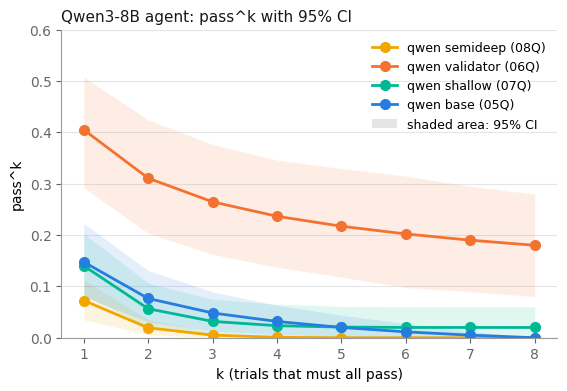

In [17]:
# Why: pass^k (k = 1..8) with 95% CI is the headline metric. The validator, shallow and baseline
# (all seeded, cell 3) are drawn in the same chart. ylim stays fixed at 0.6 so every Qwen
# notebook draws on the same axis (H7). Only this arm's csv and figure are written.
import csv, matplotlib.pyplot as plt
from matplotlib.patches import Patch
curves = {name: passk.curve(f"{ROOT}/{d}", N_TASKS)[1] for name, d, _ in ARMS
          if os.path.isdir(f"{ROOT}/{d}")}             # a missing line is skipped
show(pd.DataFrame([{"arm": n, **{f"k={r['k']}": f"{r['pass^k']:.3f}" for r in rows},
                    "95% CI k=1": f"[{rows[0]['ci_low']:.2f}, {rows[0]['ci_high']:.2f}]",
                    "drop 1→8": f"{1 - rows[-1]['pass^k'] / rows[0]['pass^k']:.0%}" if rows[0]["pass^k"] else "-"}
                   for n, rows in curves.items() if rows]))
r = curves.get(ARMS[0][0])
if r:
    with open(f"{ROOT}/{OUT}_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=r[0].keys()); w.writeheader(); w.writerows(r)
fig, ax = plt.subplots(figsize=(6.4, 4))
for name, d, color in ARMS:
    r = curves.get(name)
    if not r: continue
    ks = [x["k"] for x in r]
    ax.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], color=color, alpha=0.12, lw=0)
    ax.plot(ks, [x["pass^k"] for x in r], "-", marker="o", ms=7, lw=2, color=color, label=name)
ax.set(xlabel="k (trials that must all pass)", ylabel="pass^k", ylim=(0, 0.6), xticks=range(1, 9))
ax.set_title("Qwen3-8B agent: pass^k with 95% CI", loc="left", fontsize=11, color="#191919")
ax.spines[["top", "right"]].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#999999")
ax.tick_params(colors="#666666"); ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="#999999", alpha=0.25, label="shaded area: 95% CI"))
ax.legend(handles=handles, frameon=False, fontsize=9)
os.makedirs(f"{ROOT}/figures", exist_ok=True)
plt.savefig(f"{ROOT}/figures/{OUT}_passk.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
# Why: paired comparisons over the same tasks: per task, pass^k = C(c, k) / C(8, k) (c = passes in
# 8 trials), then the mean difference with a 95% bootstrap CI over tasks (10,000 resamples, fixed seed).
# Shown for all 50 tasks and for the 42 clean tasks (8 tasks have answer keys that break the policy).
# H1: a KiL pipeline must beat the validator, not only the baseline; the professor also asked to
# compare the three pipelines, so semi-deep − shallow is shown too. One csv per comparison, for 10Q.
import numpy as np
from math import comb
BAD_KEYS = {10, 16, 19, 26, 27, 34, 45, 46}         # answer keys that break the policy (Part 1, 06G)
KS = [1, 2, 4, 8]

def per_task(folder):
    full = {t: v for t, v in tab_of(folder).items() if len(v) == N_TASKS}
    assert len(full) == N_TRIALS, f"{folder}: {len(full)} of {N_TRIALS} trials complete"
    c = passk.success_counts(full, range(N_TASKS))
    return {k: np.array([comb(c[t], k) / comb(N_TRIALS, k) for t in range(N_TASKS)]) for k in KS}

def paired(a, b, tasks, n=10_000, seed=691):
    d = a[tasks] - b[tasks]
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return d.mean(), lo, hi

me = per_task(OUT)
TASKS = [("all 50", np.arange(N_TASKS)),
         ("clean 42", np.array([t for t in range(N_TASKS) if t not in BAD_KEYS]))]
for ref_name, ref_out, tag in COMPARE:
    if not os.path.isdir(f"{ROOT}/{ref_out}"):
        print(f"{ARM} − {ref_name}: {ref_out} not found, skipped"); continue
    ref = per_task(ref_out)
    rows = []
    for name, tasks in TASKS:
        for k in KS:
            m, lo, hi = paired(me[k], ref[k], tasks)
            rows.append({"tasks": name, "k": k, ARM: f"{me[k][tasks].mean():.3f}",
                         ref_name: f"{ref[k][tasks].mean():.3f}", f"Δ ({ARM} − {ref_name})": f"{m:+.3f}",
                         "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "significant": "*" if lo > 0 or hi < 0 else ""})
    df = pd.DataFrame(rows)
    df.to_csv(f"{ROOT}/{OUT}_{tag}.csv", index=False)
    print(f"{ARM} − {ref_name}")
    show(df)

semideep − validator


tasks,k,semideep,validator,Δ (semideep − validator),95% CI,significant
all 50,1,0.072,0.405,-0.333,"[-0.432, -0.235]",*
all 50,2,0.019,0.311,-0.291,"[-0.401, -0.189]",*
all 50,4,0.001,0.237,-0.236,"[-0.348, -0.134]",*
all 50,8,0.000,0.180,-0.180,"[-0.300, -0.080]",*
clean 42,1,0.086,0.482,-0.396,"[-0.500, -0.292]",*
clean 42,2,0.023,0.370,-0.347,"[-0.468, -0.233]",*
clean 42,4,0.001,0.282,-0.281,"[-0.407, -0.166]",*
clean 42,8,0.000,0.214,-0.214,"[-0.333, -0.095]",*


semideep − baseline


tasks,k,semideep,baseline,Δ (semideep − baseline),95% CI,significant
all 50,1,0.072,0.147,-0.075,"[-0.138, -0.018]",*
all 50,2,0.019,0.076,-0.057,"[-0.109, -0.014]",*
all 50,4,0.001,0.032,-0.031,"[-0.063, -0.006]",*
all 50,8,0.000,0.000,+0.000,"[+0.000, +0.000]",
clean 42,1,0.086,0.176,-0.089,"[-0.164, -0.021]",*
clean 42,2,0.023,0.091,-0.068,"[-0.129, -0.015]",*
clean 42,4,0.001,0.038,-0.037,"[-0.075, -0.007]",*
clean 42,8,0.000,0.000,+0.000,"[+0.000, +0.000]",


semideep − shallow


tasks,k,semideep,shallow,Δ (semideep − shallow),95% CI,significant
all 50,1,0.072,0.140,-0.068,"[-0.130, -0.010]",*
all 50,2,0.019,0.056,-0.037,"[-0.089, -0.000]",*
all 50,4,0.001,0.023,-0.023,"[-0.065, +0.000]",
all 50,8,0.000,0.020,-0.020,"[-0.060, +0.000]",
clean 42,1,0.086,0.167,-0.080,"[-0.152, -0.012]",*
clean 42,2,0.023,0.067,-0.044,"[-0.105, -0.000]",*
clean 42,4,0.001,0.028,-0.027,"[-0.077, +0.000]",
clean 42,8,0.000,0.024,-0.024,"[-0.071, +0.000]",


In [27]:
# Why: the brief's metrics, for this arm and every comparison arm of cell 3 (all seeded), from the saved
# dialogues: "Policy-violation rate, split into three types", "Violation rate by turn position
# (early, middle, late)", and "Violations on tasks that still pass on final state".
#  Type 1, illegal tool calls: rule-breaking write calls that really ran (06G's checker, replayed on
#          a fresh database copy). Blocked calls are counted apart: they never reached the database.
#  Type 2, dialogue-level violations (all executed calls; proxies, checked by hand in 07Q-09Q):
#    - skipped confirmation (G1): a booking / change ran although the user's last message had no yes
#    - skipped explanation (G1 "list the action details"): the agent did not state the reservation id
#      and the new flights / bag count / passenger names to the user before the call. Writes made
#      after one user message share one explanation (hand-check fix: a batched change was explained
#      once, then counted as unexplained for the second call).
#    - tool call and reply in the same turn (G3)
#    - forbidden statement (G2 "no subjective recommendations"): phrases like "I recommend",
#      "you should go with", "the best option is"
#  Type 3, reasoning / argument errors: write calls the database rejected; any tool call that came
#          back as an error; malformed calls (arguments not JSON, or a tool that does not exist).
# Position = message index / dialogue length, cut in thirds. Rates are per 100 dialogues.
# The first table keeps the exact columns of 05Q / 06Q, so the numbers can be checked against them.
# Only this arm's json is saved for 10Q; 05Q's and 06Q's files are never touched.
import json, re, time, importlib, violations as V, policy_checker as pc
importlib.reload(V); importlib.reload(pc)
from tau_bench.envs.airline.data import load_data
graph = pc.load_graph()
YES = re.compile(r"\b(yes|yeah|yep|yup|confirm(ed)?|go ahead|proceed|sure|please do|do it|sounds good|"
                 r"that'?s (fine|correct|right)|ok(ay)?|correct)\b", re.I)
RECO = re.compile(r"\b(i (would |'d )?(recommend|suggest)|my (recommendation|suggestion) (is|would be)|"
                  r"i think you should|you should (choose|go with|book|pick|take)|"
                  r"the best (option|choice|deal) (is|would be|for you)|i('d| would) go with)\b", re.I)
G1_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
            "update_reservation_passengers"}
TYPES = [("illegal", "1 · illegal tool call that ran"),
         ("g1_no_yes", "2 · skipped confirmation (G1)"),
         ("no_explain", "2 · skipped explanation (G1)"),
         ("g3_call_and_reply", "2 · tool call + reply in one turn (G3)"),
         ("g2_recommend", "2 · forbidden statement: recommendation (G2)"),
         ("db_rejected", "3 · write call rejected by the database"),
         ("tool_error", "3 · any tool call that returned an error"),
         ("malformed", "3 · malformed call (bad JSON / unknown tool)")]

def details(name, kw):
    # the values the agent must state before the call (G1: "list the action details")
    flights = [f.get("flight_number") for f in kw.get("flights") or [] if isinstance(f, dict)]
    rid = [kw.get("reservation_id")]
    return [v for v in {"book_reservation": flights,
                        "update_reservation_flights": rid + flights,
                        "update_reservation_baggages": rid + [kw.get("total_baggages")],
                        "update_reservation_passengers": rid + [p.get("first_name") for p in kw.get("passengers") or []
                                                                if isinstance(p, dict)]}.get(name, [])
            if v not in (None, "")]

def scan(traj):
    # replay like violations.py, keeping the position of every violation in the dialogue
    traj = [m for m in traj if isinstance(m, dict)]
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    data, hist, last_user, said, wrote = load_data(), [], "", "", False
    pos = lambda i: i / max(len(traj) - 1, 1)
    out = {k: [] for k, _ in TYPES}
    out.update(blocked=0, g1_calls=0)
    for i, m in enumerate(traj):
        if m.get("role") == "user":
            last_user = m.get("content") or ""
            if wrote: said, wrote = "", False                    # a new request: explain again
        if m.get("role") != "assistant":
            continue
        text = (m.get("content") or "").strip()
        said += " " + text.lower()
        if text and m.get("tool_calls"): out["g3_call_and_reply"].append(pos(i))
        if RECO.search(text): out["g2_recommend"].append(pos(i))
        for c in m.get("tool_calls") or []:
            name = c["function"]["name"]
            try: kw = json.loads(c["function"]["arguments"] or "{}")
            except json.JSONDecodeError: kw = None
            if name not in V.TOOLS or not isinstance(kw, dict):
                out["malformed"].append(pos(i)); continue
            if c["id"] not in obs: continue
            o = str(obs[c["id"]]); blocked = o.startswith(V.BLOCK_TAG)
            if blocked:
                out["blocked"] += name in pc.WRITE_TOOLS; continue
            if o.startswith("Error"): out["tool_error"].append(pos(i))
            if name in pc.WRITE_TOOLS:
                if pc.check(name, kw, data, hist, graph): out["illegal"].append(pos(i))
                if o.startswith("Error"): out["db_rejected"].append(pos(i))
                if name in G1_TOOLS:
                    out["g1_calls"] += 1
                    if not YES.search(last_user): out["g1_no_yes"].append(pos(i))
                    if not all(str(v).lower() in said for v in details(name, kw)): out["no_explain"].append(pos(i))
            try: res = V.TOOLS[name].invoke(data=data, **kw)
            except Exception as e: res = f"Error: {e}"
            if name in pc.WRITE_TOOLS and not str(res).startswith("Error"):
                hist.append({"name": name, "kwargs": kw}); wrote = True
    return out

third = lambda p: "early" if p < 1 / 3 else "middle" if p < 2 / 3 else "late"
compat, long_rows, t0 = [], [], time.time()
for name, d, _ in ARMS:
    if not os.path.isdir(f"{ROOT}/{d}"): continue   # a missing line is skipped
    n = npass = 0
    tot = {k: {"count": 0, "early": 0, "middle": 0, "late": 0, "passing dialogues with it": 0} for k, _ in TYPES}
    blocked = g1_calls = 0
    for tasks in tab_of(d).values():
        for r in tasks.values():
            s = scan(r.get("traj") or [])
            n += 1; ok = r["reward"] >= 1 - 1e-6; npass += ok
            blocked += s["blocked"]; g1_calls += s["g1_calls"]
            for k, _ in TYPES:
                tot[k]["count"] += len(s[k])
                for p in s[k]: tot[k][third(p)] += 1
                tot[k]["passing dialogues with it"] += ok and len(s[k]) > 0
    i, g = tot["illegal"], tot["g1_no_yes"]
    compat.append({"arm": name, "blocked calls": blocked, "illegal calls run": i["count"],
                   "early / middle / late": f'{i["early"]} / {i["middle"]} / {i["late"]}',
                   "G1: write without a yes": f'{g["count"]}/{g1_calls}',
                   "argument errors": tot["db_rejected"]["count"],
                   "passing dialogues with a violation": f'{i["passing dialogues with it"]}/{npass}'})
    for k, label in TYPES:
        t = tot[k]
        long_rows.append({"type": label, "arm": name, "count": t["count"], "per 100 dialogues": f'{100 * t["count"] / max(n, 1):.1f}',
                          "early / middle / late": f'{t["early"]} / {t["middle"]} / {t["late"]}',
                          "passing dialogues with it": f'{t["passing dialogues with it"]}/{npass}'})
    if d == OUT:
        json.dump({"dialogues": n, "passed": npass, "blocked": blocked, "g1_calls": g1_calls, "types": tot,
                   # the 05Q / 06Q keys, for 10Q
                   "illegal": i["count"], "g1_miss": g["count"], "arg_err": tot["db_rejected"]["count"],
                   "early": i["early"], "middle": i["middle"], "late": i["late"], "passed dialogues": npass,
                   "passed with ≥1 illegal": i["passing dialogues with it"]},
                  open(f"{ROOT}/{OUT}_violations.json", "w"), indent=2)
print("Same columns as 05Q / 06Q (check against them):")
show(pd.DataFrame(compat))
print("All violation types (brief: three types, by turn position, on passing dialogues):")
order = {label: j for j, (_, label) in enumerate(TYPES)}
show(pd.DataFrame(long_rows).sort_values("type", key=lambda s: s.map(order), kind="stable"))
print(f"scanned in {time.time() - t0:.0f} s; saved {OUT}_violations.json")

Same columns as 05Q / 06Q (check against them):


arm,blocked calls,illegal calls run,early / middle / late,G1: write without a yes,argument errors,passing dialogues with a violation
qwen semideep (08Q),0,451,106 / 154 / 191,644/946,492,7/29
qwen validator (06Q),390,0,0 / 0 / 0,261/422,173,0/162
qwen shallow (07Q),0,462,159 / 128 / 175,396/654,352,8/56
qwen base (05Q),0,363,95 / 122 / 146,359/598,258,3/59


All violation types (brief: three types, by turn position, on passing dialogues):


type,arm,count,per 100 dialogues,early / middle / late,passing dialogues with it
1 · illegal tool call that ran,qwen semideep (08Q),451,112.8,106 / 154 / 191,7/29
1 · illegal tool call that ran,qwen validator (06Q),0,0.0,0 / 0 / 0,0/162
1 · illegal tool call that ran,qwen shallow (07Q),462,115.5,159 / 128 / 175,8/56
1 · illegal tool call that ran,qwen base (05Q),363,90.8,95 / 122 / 146,3/59
2 · skipped confirmation (G1),qwen semideep (08Q),644,161.0,99 / 261 / 284,8/29
2 · skipped confirmation (G1),qwen validator (06Q),261,65.2,38 / 98 / 125,22/162
2 · skipped confirmation (G1),qwen shallow (07Q),396,99.0,90 / 140 / 166,16/56
2 · skipped confirmation (G1),qwen base (05Q),359,89.8,58 / 159 / 142,14/59
2 · skipped explanation (G1),qwen semideep (08Q),914,228.5,120 / 344 / 450,9/29
2 · skipped explanation (G1),qwen validator (06Q),286,71.5,25 / 100 / 161,19/162


scanned in 89 s; saved results_qwen_semideep_violations.json


In [20]:
# Why: semi-deep's own record. Every agent step logged a plan (which graph action) and a check (each
# cited node: holds / does not hold / unknown). This shows what the agent planned, how it judged the
# rules, how often it had to be asked again ("must cite"), and whether its next step followed its own
# check: a write call although one of that action's conditions "does not hold" is acting against its
# own check (the brief's "generation is conditioned on that check" not working).
import collections
G_ = sdr.G if "sdr" in dir() else __import__("graph_text").load()
TOOL_OF = {a["action"]: a["tool"] for a in G_["actions"]}
rows, per_trial = [], []
for t in range(1, N_TRIALS + 1):
    f = f"{ROOT}/{OUT}/trial_{t}/plans.jsonl"
    rs = [json.loads(l) for l in open(f)] if os.path.exists(f) else []
    rows += rs
    per_trial.append({"trial": t, "steps checked": len(rs),
                      "plan asked again": sum(bool(r.get("plan_retry")) for r in rs),
                      "check asked again": sum(bool(r.get("check_retry")) for r in rs)})
show(pd.DataFrame(per_trial))
acts = collections.Counter(a for r in rows for a in r["action"].split(","))
show(pd.DataFrame([{"planned action": a, "steps": n, "share": f"{n / max(len(rows), 1):.0%}"} for a, n in acts.most_common()]))
verd = collections.Counter(v for r in rows for v, _ in r["check"].values())
nv = sum(verd.values())
show(pd.DataFrame([{"verdict": v, "cited nodes": verd[v], "share": f"{verd[v] / max(nv, 1):.0%}"}
                   for v in ("holds", "does not hold", "unknown", "not cited")]))
def follows(r):
    # the next step is a write call for one of the planned actions: did that action's own check allow it?
    if r["action"] == "none" or not r["next"].startswith("tool:"):
        return None
    hit = [a for a in r["action"].split(",") if TOOL_OF.get(a) == r["next"][5:]]
    if not hit:
        return None
    conds = {i: v for i, (v, _) in r["check"].items() if any(i.startswith(f"{a}/c") for a in hit)}
    return "against own check" if any(v == "does not hold" for v in conds.values()) else "check allowed it"
w = collections.Counter(x for x in map(follows, rows) if x)
refused = sum(1 for r in rows if r["action"] != "none" and r["next"] == "reply"
              and any(v == "does not hold" for i, (v, _) in r["check"].items() if "/c" in i))
yes_missing = sum(1 for r in rows if follows(r) and r["check"].get("G/G1", ("",))[0] == "does not hold")
show(pd.DataFrame([{"next step after the check": "planned write call made, check allowed it", "steps": w["check allowed it"]},
                   {"next step after the check": "planned write call made AGAINST its own check", "steps": w["against own check"]},
                   {"next step after the check": "replied instead (a condition does not hold)", "steps": refused},
                   {"next step after the check": "write call made while its own check said 'no explicit yes yet' (G1)", "steps": yes_missing}]))
json.dump({"steps": len(rows), "actions": dict(acts), "verdicts": dict(verd), "writes_allowed": w["check allowed it"],
           "writes_against_check": w["against own check"], "refused_after_check": refused, "write_without_yes_by_own_check": yes_missing,
           "plan_retry": sum(p["plan asked again"] for p in per_trial), "check_retry": sum(p["check asked again"] for p in per_trial)},
          open(f"{ROOT}/{OUT}_plans.json", "w"), indent=2)
print(f"saved {OUT}_plans.json")

trial,steps checked,plan asked again,check asked again
1,789,64,46
2,741,68,46
3,886,82,41
4,857,52,50
5,781,76,37
6,942,79,39
7,812,59,45
8,914,72,42


planned action,steps,share
cancel_reservation,2846,42%
update_reservation_flights,2465,37%
book_reservation,851,13%
update_reservation_baggages,817,12%
send_certificate,804,12%
none,674,10%
update_reservation_passengers,419,6%
upgrade_cabin,224,3%


verdict,cited nodes,share
holds,51394,65%
does not hold,6452,8%
unknown,20742,26%
not cited,0,0%


next step after the check,steps
"planned write call made, check allowed it",1405
planned write call made AGAINST its own check,124
replied instead (a condition does not hold),647
write call made while its own check said 'no explicit yes yet' (G1),8


saved results_qwen_semideep_plans.json


In [21]:
# Why: which tasks each arm solves every time, never, or only sometimes; the unseeded run shows how
# much these counts move between two runs of the same arm. Only this arm's json is saved.
cons = {}
for name, d, _ in ARMS:
    if not os.path.isdir(f"{ROOT}/{d}"): continue   # a missing line is skipped
    full = {t: v for t, v in tab_of(d).items() if len(v) == N_TASKS}
    c = passk.success_counts(full, range(N_TASKS))
    cons[name] = {"always pass": len([t for t in c if c[t] == N_TRIALS]),
                  "sometimes": len([t for t in c if 0 < c[t] < N_TRIALS]),
                  "never pass": len([t for t in c if c[t] == 0])}
json.dump(cons[ARMS[0][0]], open(f"{ROOT}/{OUT}_consistency.json", "w"), indent=2)
show(pd.DataFrame(cons).rename_axis("type").reset_index())

type,qwen semideep (08Q),qwen validator (06Q),qwen shallow (07Q),qwen base (05Q)
always pass,0,9,1,0
sometimes,13,23,20,18
never pass,37,18,29,32


In [28]:
# Why: brief: "hand-check 30 failed trajectories to confirm whether errors come from the agent or the
# simulator". Plan: 15 per KiL pipeline (07Q shallow, 08Q semi-deep, 09Q deep) = 45 in total.
# This cell picks 15 failed dialogues of this arm (fixed seed, so the same 15 every time):
# first one per "sometimes" task (passes in some trials, fails in others: the clearest test of who is
# at fault), then one per "never" task, then a second dialogue per task until there are 15. Each one
# is written as a readable file, and a sheet lists them with automatic hints and an empty label.
# Open handcheck/labels.xlsx in Drive (it opens in Google Sheets and saves back as .xlsx), read each
# dialogue, and pick a label: agent / simulator / benchmark / unclear. Never overwritten once written.
import random
from openpyxl import load_workbook
from openpyxl.worksheet.datavalidation import DataValidation
N_HC, LABELS_OK = 15, ["agent", "simulator", "benchmark", "unclear"]
HC = f"{ROOT}/{OUT}_handcheck"
SHEET = f"{HC}/labels.xlsx"

def plans_of(task, trial):
    f = f"{ROOT}/{OUT}/trial_{trial}/plans.jsonl"
    rs = [json.loads(l) for l in open(f)] if os.path.exists(f) else []
    return {r["step"]: r for r in rs if r["task_id"] == task}     # a rerun overwrites its own steps

def as_markdown(r, task, trial):
    lines = [f"# {OUT}: task {task}, trial {trial}, reward {r['reward']}", ""]
    plans, n = plans_of(task, trial), 0
    for m in (r.get("traj") or []):
        if isinstance(m, dict) and m.get("role") == "assistant":
            n += 1
            p = plans.get(n)
            if p:
                bad = [f"{i} ({e[:60]})" for i, (v, e) in p["check"].items() if v == "does not hold"]
                unk = [i for i, (v, _) in p["check"].items() if v == "unknown"]
                lines.append(f"> *planning state, step {n}:* {p['action']} | plan: {p['plan'][:160]} | "
                             f"does not hold: {'; '.join(bad) or '-'} | unknown: {', '.join(unk) or '-'}")
        if not isinstance(m, dict) or m.get("role") == "system": continue
        if m.get("role") == "tool":
            lines.append(f"> **tool result:** {str(m.get('content'))[:400]}")
        else:
            if (m.get("content") or "").strip():
                lines.append(f"**{m['role']}:** {m['content'].strip()}")
            for c in m.get("tool_calls") or []:
                lines.append(f"**{m['role']} calls** `{c['function']['name']}({c['function']['arguments']})`")
        lines.append("")
    return "\n".join(lines)

if os.path.exists(SHEET):
    print(f"{SHEET.replace(ROOT, 'project2')} already exists: kept as it is (labels are never overwritten)")
else:
    tab = tab_of(OUT)
    full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
    c = passk.success_counts(full, range(N_TASKS))
    failed = {t: [tr for tr in sorted(full) if full[tr][t]["reward"] < 1 - 1e-6 and not passk.is_error(full[tr][t])]
              for t in range(N_TASKS)}
    rng = random.Random(691)
    sometimes = [t for t in range(N_TASKS) if 0 < c[t] < N_TRIALS and failed[t]]
    never = [t for t in range(N_TASKS) if c[t] == 0 and failed[t]]
    rng.shuffle(sometimes); rng.shuffle(never)
    for t in failed: rng.shuffle(failed[t])
    picks, round_ = [], 0
    while len(picks) < N_HC and any(len(failed[t]) > round_ for t in sometimes + never):
        for t in sometimes + never:
            if len(failed[t]) > round_ and len(picks) < N_HC:
                picks.append((t, failed[t][round_]))
        round_ += 1
    os.makedirs(HC, exist_ok=True)
    rows = []
    for j, (task, trial) in enumerate(picks, 1):
        r = full[trial][task]
        s = scan(r.get("traj") or [])
        hints = [label for k, label in TYPES if s[k]]
        last = next((m for m in reversed(r.get("traj") or []) if isinstance(m, dict) and m.get("role") == "assistant"), {})
        ends = ", ".join(c_["function"]["name"] for c_ in last.get("tool_calls") or []) or "text reply"
        fname = f"{j:02d}_task{task:02d}_trial{trial}.md"
        open(f"{HC}/{fname}", "w").write(as_markdown(r, task, trial))
        rows.append({"id": j, "task": task, "trial": trial,
                     "task type": "sometimes" if task in sometimes else "never",
                     "answer key breaks the policy": "yes" if task in BAD_KEYS else "",
                     "automatic hints": "; ".join(hints) or "none", "agent's last action": ends,
                     "file": fname, "label": "", "note": ""})
    pd.DataFrame(rows).to_excel(SHEET, index=False)
    wb = load_workbook(SHEET); ws = wb.active                  # a drop-down for the label column
    dv = DataValidation(type="list", formula1='"' + ",".join(LABELS_OK) + '"', allow_blank=True)
    ws.add_data_validation(dv); dv.add(f"I2:I{len(rows) + 1}")
    for col, w in zip("ABCDEFGHIJ", [4, 6, 6, 11, 12, 45, 28, 26, 12, 40]): ws.column_dimensions[col].width = w
    wb.save(SHEET)
    print(f"wrote {len(rows)} dialogues + labels.xlsx to {HC.replace(ROOT, 'project2')}")
hc = pd.read_excel(SHEET)
show(hc.groupby(["task type"]).agg(dialogues=("id", "count"), tasks=("task", "nunique")).reset_index())

project2/results_qwen_semideep_handcheck/labels.xlsx already exists: kept as it is (labels are never overwritten)


task type,dialogues,tasks
never,2,2
sometimes,13,13


In [29]:
# Why: label the 15 hand-check dialogues inside Colab, one at a time: read the dialogue, type a short
# reason (optional), click who is at fault. Each click saves to labels.xlsx at once and opens the next
# dialogue. Run cell 15 first. Safe to stop and come back: it starts at the first row without a label.
import ipywidgets as W
from IPython.display import Markdown, clear_output
from openpyxl import load_workbook
hc = pd.read_excel(SHEET).fillna("")
state = {"i": next((j for j, l in enumerate(hc.label) if not str(l).strip()), 0)}
box, status = W.Output(), W.HTML()
note = W.Text(placeholder="optional: one short reason, e.g. 'cancelled a flown trip (C3)'",
              layout=W.Layout(width="80%"))

def save_row(j, label, text):
    wb = load_workbook(SHEET); ws = wb.active                 # keeps the drop-down in the sheet
    ws[f"I{j + 2}"] = label; ws[f"J{j + 2}"] = text; wb.save(SHEET)
    hc.loc[j, "label"], hc.loc[j, "note"] = label, text

def show_row():
    j = state["i"]; r = hc.iloc[j]
    done = sum(bool(str(l).strip()) for l in hc.label)
    with box:
        clear_output()
        display(Markdown(f"### Dialogue {j + 1} of {len(hc)} · task {r.task}, trial {r.trial} · labelled {done}/{len(hc)}\n\n"
                         f"**Automatic hints:** {r['automatic hints']}  \n"
                         f"**Answer key breaks the policy:** {r['answer key breaks the policy'] or 'no'}  \n"
                         f"**Current label:** {r.label or '-'}\n\n---"))
        display(Markdown(open(f"{HC}/{r.file}").read()))
    note.value = str(r.note)

def pick(label):
    def click(_):
        save_row(state["i"], label, note.value.strip())
        status.value = f"✅ saved dialogue {state['i'] + 1}: <b>{label}</b>"
        if state["i"] < len(hc) - 1: state["i"] += 1
        show_row()
    return click

def move(step):
    def click(_):
        state["i"] = min(max(state["i"] + step, 0), len(hc) - 1); show_row()
    return click

buttons = [W.Button(description=l, button_style=s) for l, s in zip(LABELS_OK, ["danger", "warning", "info", ""])]
for b, l in zip(buttons, LABELS_OK): b.on_click(pick(l))
back, skip = W.Button(description="◀ back"), W.Button(description="skip ▶")
back.on_click(move(-1)); skip.on_click(move(1))
display(W.VBox([note, W.HBox(buttons + [back, skip]), status, box]))
show_row()

In [30]:
# Why: read back the hand-check labels and answer the brief's question: do the errors come from the
# agent or the simulator? Run after labelling all 15 dialogues (cell 16). The result is saved for 10Q.
hc = pd.read_excel(SHEET)
hc["label"] = hc["label"].fillna("").astype(str).str.strip().str.lower()
bad = hc[(hc.label != "") & ~hc.label.isin(LABELS_OK)]
todo = int((hc.label == "").sum())
assert bad.empty, f"rows {bad.id.tolist()} have labels other than {LABELS_OK}"
if todo:
    print(f"{todo} of {len(hc)} dialogues still have no label: finish labels.xlsx, then run this cell again")
else:
    counts = hc.label.value_counts().reindex(LABELS_OK, fill_value=0)
    out = pd.DataFrame({"cause": counts.index, "dialogues": counts.values,
                        "share": [f"{v / len(hc):.0%}" for v in counts.values]})
    show(out)
    show(pd.crosstab(hc["task type"], hc["label"]).reset_index())
    json.dump({"n": len(hc), **counts.to_dict()}, open(f"{ROOT}/{OUT}_handcheck.json", "w"), indent=2)
    print(f"saved {OUT}_handcheck.json")

cause,dialogues,share
agent,15,100%
simulator,0,0%
benchmark,0,0%
unclear,0,0%


task type,agent
never,2
sometimes,13


saved results_qwen_semideep_handcheck.json


## Summary

**Run:** L4 (22 GB), vLLM 0.34.0, 24k context (full setting 32k; note in the report), max-num-seqs 8, 50 tasks × 8 trials, simulator seed = trial number, semideep_run.py id 7dd0a89f. Seed check (cell 7): Gemini accepts seed: yes; same seed repeats the reply: yes; check lines read: 100%. Full run about 11 h on an L4 (three model calls per agent step, about 4× the baseline). Passed per trial: 2 / 3 / 3 / 3 / 4 / 3 / 5 / 6.

**Run notes:**
- A first full run (2026-11-26 night) was lost: its files were never synced to Drive before the Colab session ended (a folder rename followed by a new folder with the same name broke the sync). This run was started from scratch on 2026-11-27; the earlier partial runs are kept as `results_qwen_semideep_old_26e38201` and `results_qwen_semideep_aborted_1127`, not used.
- Mid-run, the Gemini API prepaid balance ran out (`PaymentRequiredError`); those tasks did not run and were run after a top-up. This is an account error, not a task failure, so it does not count as a rerun.
- 8 of 400 dialogues failed on the first pass (a tool reply τ-bench could not parse, or the 24k context limit) and were rerun once; 7 finished. Trial 8 task 28 hit the 24k limit again and counts as a fail (399/400 completed).

| | pass^1 (95% CI) | pass^8 | drop 1→8 | illegal calls run | G1: write without a yes | passing with a violation |
|---|---|---|---|---|---|---|
| **Qwen semi-deep (08Q)** | 0.072 [0.04, 0.11] | 0.000 | 100% | 451 | 644/946 | 7/29 |
| Qwen validator (06Q) | 0.405 [0.29, 0.51] | 0.180 | 56% | 0 (390 blocked) | 261/422 | 0/162 |
| Qwen shallow (07Q) | 0.140 [0.08, 0.20] | 0.020 | 86% | 462 | 396/654 | 8/56 |
| Qwen base (05Q) | 0.147 [0.08, 0.22] | 0.000 | 100% | 363 | 359/598 | 3/59 |

**Paired (cell 11, 10,000 resamples, * = 95% CI excludes 0):**
- semi-deep − validator: Δpass^1 = −0.333 [−0.432, −0.235]\*, Δpass^8 = −0.180 [−0.300, −0.080]\*; significant at every k (clean 42: −0.396\*, −0.214\*).
- semi-deep − baseline: Δpass^1 = −0.075 [−0.138, −0.018]\*, Δpass^8 = +0.000; significant at k = 1, 2, 4 (clean 42: −0.089\*).
- semi-deep − shallow: Δpass^1 = −0.068 [−0.130, −0.010]\*, Δpass^8 = −0.020 [−0.060, +0.000]; significant at k = 1, 2 (clean 42: −0.080\*).

**Violations by type (cell 12, per 100 dialogues; counts early / middle / late):**
- Type 1, illegal calls: 112.8 (106 / 154 / 191); base 90.8, shallow 115.5, validator 0.
- Type 2: skipped confirmation 161.0 (99 / 261 / 284), skipped explanation 228.5 (120 / 344 / 450), call + reply 2.8 (5 / 3 / 3), recommendation 0.8 (0 / 1 / 2). Base: 89.8 / 97.5 / 2.8 / 12.2.
- Type 3: database-rejected 123.0 (59 / 207 / 226), tool errors 183.5 (189 / 267 / 278), malformed 47.8 (46 / 72 / 73). Base: 64.5 / 106.5 / 4.8.
- Semi-deep makes far more writes than any other arm (946 vs 598 for the baseline), and a larger share of them have no explicit yes (68% vs 60%). Only recommendation phrases fall (0.8 vs 12.2).

**Planning states (cell 13):** 6,722 steps checked, 0 nodes left uncited; plan asked again about 8%, check about 5%. Verdicts: holds 65%, does not hold 8%, rest unknown. Write calls its check allowed: 1,405; write calls against its own check: 124; replies instead of a write after a "does not hold": 647. Its own check flagged a missing yes (G1) before only 8 writes, while the proxy finds 644 writes without a yes.

**Consistency (cell 14):** always / sometimes / never pass: 0 / 13 / 37 (base 0 / 18 / 32; shallow 1 / 20 / 29; validator 9 / 23 / 18).

**Hand-check, 15 failed dialogues (cell 17; 45 in total with 07Q and 09Q):** agent / simulator / benchmark / unclear = 15 / 0 / 0 / 0 (13 from "sometimes" tasks, 2 from "never"). Three patterns: (1) the check is too lenient: it marks rules as holding or unknown and does not flag the missing yes (G1) or a flown trip (C3); (2) the agent acts against its own check: the check says a rule does not hold (basic economy cannot change flights, cancellation not allowed), and the agent changes or cancels anyway; (3) as in 07Q, it invents ids, picks the wrong reservation, and loops on the same call. The check sometimes works: in several dialogues the agent correctly answered NO after its check, then gave in when the user pushed.

**H1 (semi-deep):** not supported on Qwen3-8B. Semi-deep follows the brief (plan → graph nodes → cite each → act, at every step, no veto), but it is the lowest of all four arms: below the validator at every k, and below the baseline and shallow at pass^1. The graph shapes the plan, but an 8B model judges its own plan too leniently and does not reliably follow its own check. A check by code (the validator) is far more reliable than a check by the same model. The extra planning text also makes each step longer: more malformed calls, more tool errors, more context-limit failures, about 4× the compute.

**Next:** 09Q, Qwen deep KiL.